# 34회 후기 유형 연습 해설

공식 원문·정답이 아닌 창작 합성 자료입니다. README와 출처·보완 명세를 먼저 확인하세요. Python 3.12 별도 실행 환경을 사용합니다. 아래 문제 지문은 PDF와 같으며 설명 셀의 선택 근거·가정·가설과 실행 출력의 계산값·기각 여부·상황 결론을 함께 읽으세요. `분석코드.py`로 같은 계산을 일괄 실행할 수 있습니다.

In [1]:
from pathlib import Path
import sys
FOLDER = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
repo = next(p for p in [FOLDER]+list(FOLDER.parents) if (p/'tools/exams').is_dir())
sys.path.insert(0,str(repo/'기출문제/유형연습/공통'))
from analysis import Context
ctx=Context(FOLDER)


## 1. 부분 관측 라벨을 이용한 후속 예측

clinical.csv는 age·bp·signal·s1~s3·ind·dead다. s1~s3는 0~2 서열이며, 세 값이 다 있으면 합≥4일 때 bleed=1, 아니면0으로 생성한다. 결측이 있으면 bleed는 미관측이다. ind=0은 bleed 관측 학습,1은 bleed 미관측 학습,2는 최종 시험이다. bleed 예측 입력은 age·bp·signal만 허용한다. 이 규칙·라벨은 실제 의료 기준이 아닌 창작 조건이다.

### 1-1

**문제** 서열값·결측·ind 규칙을 검증해 bleed를 만들고 누락 범주가 보존된 빈도/교차표를 제시하시오. ind=2의 정답은 평가 외에 사용하지 마시오.

**풀이·선택 근거·해석**

결측 포함 조건문을 먼저 처리하고 dropna=False로 빈도를 확인한다. 라벨 정의에 직접 쓴 s1~s3를 bleed 예측 입력에서 제외한다.

In [2]:
ctx.run('1-1', 'clinical_prepare')


=== 1-1 ===
bleed table with missing
{
  "(0, 0.0)": 155,
  "(0, 1.0)": 25,
  "(1, nan)": 60,
  "(2, 0.0)": 50,
  "(2, 1.0)": 10
}


### 1-2

**문제** 관측 학습 라벨로 선형 및 앙상블 분류기를 내부 CV로 비교하시오. 관측 학습 행에는 out-of-fold 확률을, 미관측 학습 및 최종 시험에는 학습 모형 예측을 생성하고 관측 시험 bleed의 F1·AUC를 보고하시오.

**풀이·선택 근거·해석**

후속 학습용 예측을 자기 행을 본 모형의 in-sample 값으로 채우지 않는다. CV 선택 뒤 고정 모형의 OOF는 독립 최종 시험 평가와 구분한다.

In [3]:
ctx.run('1-2', 'clinical_oof')


=== 1-2 ===
bleed prediction
{
  "CV": {
    "Logistic": 0.7388888888888889,
    "RF": 0.6536130536130537
  },
  "chosen": "Logistic",
  "OOF_rows": 180,
  "unknown_rows": 60,
  "test_F1": 0.6666666666666666,
  "test_AUC": 0.968
}
stage1 split
{
  "training_ids": [
    1,
    2,
    3,
    6,
    7,
    9,
    11,
    13,
    14,
    17,
    18,
    19,
    21,
    22,
    23,
    26,
    27,
    29,
    31,
    33,
    34,
    37,
    38,
    39,
    41,
    42,
    43,
    46,
    47,
    49,
    51,
    53,
    54,
    57,
    58,
    59,
    61,
    62,
    63,
    66,
    67,
    69,
    71,
    73,
    74,
    77,
    78,
    79,
    81,
    82,
    83,
    86,
    87,
    89,
    91,
    93,
    94,
    97,
    98,
    99,
    101,
    102,
    103,
    106,
    107,
    109,
    111,
    113,
    114,
    117,
    118,
    119,
    121,
    122,
    123,
    126,
    127,
    129,
    131,
    133,
    134,
    137,
    138,
    139,
    141,
    142,
    143,
    146,
    147

### 1-3

**문제** age·bp·signal과 앞 단계 예측확률을 사용해 dead를 예측하시오. bleed를 관측 여부에 따라 진짜/예측 라벨로 섞지 않고, 시험 데이터에서 앞 단계 오차가 전파되는 한계를 설명하시오.

**풀이·선택 근거·해석**

관측 여부와 무관하게 예측확률을 후속 특성으로 통일한다. 최종 시험의 bleed 정답·dead는 학습·모형 선택에서 제외한다.

In [4]:
ctx.run('1-3', 'clinical_dead')


=== 1-3 ===
dead holdout
{
  "F1": 0.5116279069767442,
  "AUC": 0.6662749706227967,
  "features": [
    "age",
    "bp",
    "signal",
    "bleed_pred"
  ],
  "train_ids": [
    1,
    2,
    3,
    4,
    6,
    7,
    8,
    9,
    11,
    12,
    13,
    14,
    16,
    17,
    18,
    19,
    21,
    22,
    23,
    24,
    26,
    27,
    28,
    29,
    31,
    32,
    33,
    34,
    36,
    37,
    38,
    39,
    41,
    42,
    43,
    44,
    46,
    47,
    48,
    49,
    51,
    52,
    53,
    54,
    56,
    57,
    58,
    59,
    61,
    62,
    63,
    64,
    66,
    67,
    68,
    69,
    71,
    72,
    73,
    74,
    76,
    77,
    78,
    79,
    81,
    82,
    83,
    84,
    86,
    87,
    88,
    89,
    91,
    92,
    93,
    94,
    96,
    97,
    98,
    99,
    101,
    102,
    103,
    104,
    106,
    107,
    108,
    109,
    111,
    112,
    113,
    114,
    116,
    117,
    118,
    119,
    121,
    122,
    123,
    124,
    126,
    

## 2. 발전량과 기상자료

power.csv의 date·kind와 p00·p12를 합해 일별 generation을 만들고 날씨와 결합한다. weather_power.csv는 날짜 키가 유일하다. 2021~2022 학습,2023 최종 시험이다. 날짜 관측은 연속되므로 독립 검정의 한계를 고려한다.

### 2-1

**문제** 일별 발전량을 구성·결합하고 계절을 만들며 변수별 기술통계와 기상변수-발전량 관계를 제시하시오. 계절별 평균 차이를 단정하기 전에 시간 의존성을 설명하시오.

**풀이·선택 근거·해석**

합계와 키 유일성을 검증한다. 상관은 기술통계로 제시하고 날짜가 독립이 아님을 고려한다. 단순 ANOVA p값을 확증적 계절 효과로 해석하지 않는다.

In [5]:
ctx.run('2-1', 'power_merge')


=== 2-1 ===
merge validation
{
  "rows": 79,
  "input_days": 79,
  "unmatched": 0,
  "description": [
    {
      "index": "count",
      "date": 79,
      "generation": 79.0,
      "temp": 79.0,
      "wind": 79.0,
      "weather_missing": 79.0,
      "weekend": 79.0,
      "season": 79.0
    },
    {
      "index": "mean",
      "date": "2022-07-01 00:00:00",
      "generation": 93.8463542607595,
      "temp": 14.999999999240503,
      "wind": 5.412261731392405,
      "weather_missing": 0.0,
      "weekend": 0.0,
      "season": 2.5569620253164556
    },
    {
      "index": "min",
      "date": "2021-01-01 00:00:00",
      "generation": 60.6457844,
      "temp": 5.07291126,
      "wind": 1.02847183,
      "weather_missing": 0.0,
      "weekend": 0.0,
      "season": 1.0
    },
    {
      "index": "25%",
      "date": "2021-10-01 00:00:00",
      "generation": 86.015113,
      "temp": 8.36877342,
      "wind": 3.0808282900000004,
      "weather_missing": 0.0,
      "weekend": 0.0,


### 2-2

**문제** 선형 및 비선형 회귀기를 시간순 CV로 선택해 최종 연도의 성능을 비교하시오. 미래 날짜의 실측 날씨가 필요하다는 가정과 실제 예보 운영의 차이를 설명하시오.

**풀이·선택 근거·해석**

동시점 날씨가 주어진 조건부 예측 연습이다. 실제 사전 발전량 예보를 주장하려면 날씨 예보와 지연/가용성 검증이 추가로 필요하다.

In [6]:
ctx.run('2-2', 'power_models')


=== 2-2 ===
CV selection
{
  "scores": {
    "Linear": 5.112146505210067,
    "RF": 9.708054847450144,
    "GB": 9.40259718269696
  },
  "chosen": "Linear",
  "metric": "RMSE",
  "selection": "training CV only"
}
holdout
{
  "RMSE": 4.779782135388776,
  "MAE": 3.5070831185206055,
  "R2": 0.8746336579666929,
  "n": 26
}
split IDs
{
  "train_index": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    44,
    45,
    46,
    47,
    48,
    49,
    50,
    51,
    52
  ],
  "test_index": [
    53,
    54,
    55,
    56,
    57,
    58,
    59,
    60,
    61,
    62,
    63,
    64,
    65,
    66,
    67,
    68,
    69,
    70,
    71,
    72,
    73,
    74,
    75,
    76,
    77,
    78
  ]


## 3. 학습법과 학생 성취

learning.csv는 성별 집단별 학생이 세 학습법을 모두 경험한 완전 균형 반복측정 자료다. 학생은 독립, 각 학생 내 측정은 연관된다. 정규 오차·집단 간 공분산 동일을 가정하고 구형성은 보장하지 않는다. score.csv는 다른 독립 학생 표본이다.

### 3-1

**문제** 성별·학습법·상호작용을 평가할 설계를 선택하고 효과별 H0/H1·F·자유도·p-value·기각 여부를 제시하시오. 반복측정을 반영하고 within 효과에는 Greenhouse-Geisser 보정을 적용하시오.

**풀이·선택 근거·해석**

성별 between×학습법 within 혼합 분산분석이다. 학생 내 반복을 독립 행으로 취급하지 않는다. within·상호작용의 df를 epsilon으로 보정하며 성별 효과는 학생 평균 오차항을 사용한다.

In [7]:
ctx.run('3-1', 'mixed_anova')


=== 3-1 ===
mixed SS/GG
{
  "epsilon": 0.8106931458746416,
  "table": [
    {
      "effect": "gender",
      "SS": 203.41887202000072,
      "F": 1.7367676467358266,
      "df1": 1.0,
      "df2": 46.0,
      "p_value": 0.19407456732192951,
      "raw_df1": 1,
      "raw_df2": 46,
      "p_uncorrected": 0.19407456732192951
    },
    {
      "effect": "method",
      "SS": 1308.0532868046046,
      "F": 33.55433949470399,
      "df1": 1.6213862917492832,
      "df2": 74.58376942046702,
      "p_value": 6.857220089730149e-10,
      "raw_df1": 2,
      "raw_df2": 92,
      "p_uncorrected": 1.1384711722835545e-11
    },
    {
      "effect": "interaction",
      "SS": 7.454641824307753,
      "F": 0.19122736444116042,
      "df1": 1.6213862917492832,
      "df2": 74.58376942046702,
      "p_value": 0.7802017413359921,
      "raw_df1": 2,
      "raw_df2": 92,
      "p_uncorrected": 0.8262722284505636
    }
  ],
  "subjects": 48
}
{
  "method": "Mixed ANOVA gender",
  "H0": "gender margin

### 3-2

**문제** 학습법별 차이를 같은 학생끼리 후속 비교하고 세 쌍의 원/보정 p-value·가설·기각 여부를 제시하시오. 상호작용이 유의할 때 주효과 후속 비교만으로 충분한지 설명하시오.

**풀이·선택 근거·해석**

대응 t 쌍별 비교에 Holm 보정을 적용한다. 상호작용이 유의하면 성별별 단순 효과 등 별도 가족 정의와 보정이 필요하다. 독립 Tukey를 반복측정에 그대로 쓰지 않는다.

In [8]:
ctx.run('3-2', 'mixed_posthoc')


=== 3-2 ===
{
  "method": "Paired t online-hybrid",
  "H0": "mean within-person difference=0",
  "H1": "mean difference !=0",
  "statistic": -5.851493459356295,
  "p_value": 4.51301811997095e-07,
  "df": 47,
  "alpha": 0.05,
  "reject_H0": true,
  "conclusion": "유의수준 5%에서 online와 hybrid의 평균 차이에 대한 근거가 있다.",
  "adjusted_p_value": 9.0260362399419e-07
}
{
  "method": "Paired t online-traditional",
  "H0": "mean within-person difference=0",
  "H1": "mean difference !=0",
  "statistic": -8.33125661017866,
  "p_value": 8.195819352049765e-11,
  "df": 47,
  "alpha": 0.05,
  "reject_H0": true,
  "conclusion": "유의수준 5%에서 online와 traditional의 평균 차이에 대한 근거가 있다.",
  "adjusted_p_value": 2.4587458056149297e-10
}
{
  "method": "Paired t hybrid-traditional",
  "H0": "mean within-person difference=0",
  "H1": "mean difference !=0",
  "statistic": -3.1440505060670296,
  "p_value": 0.0028859850250846364,
  "df": 47,
  "alpha": 0.05,
  "reject_H0": true,
  "conclusion": "유의수준 5%에서 hybrid와 traditional의 평균 

### 3-3

**문제** 독립 학생의 score를 study·failures·absences·support·internet으로 설명하시오. 전체 검정·계수·잔차 진단과 설명력, 단위가 다른 계수를 크기만으로 비교하는 문제를 설명하시오.

**풀이·선택 근거·해석**

전체 F와 잔차 가정은 별개다. 계수의 원 단위와 기준 범주를 확인하고 표준화 효과·불확실성·도메인을 함께 고려한다.


=== 3-3 ===
coefficients
[
  {
    "index": "const",
    "coef": 50.6088432958483,
    "SE": 2.531342024093407,
    "t": 19.992890259060793,
    "p": 1.5576678802139888e-52
  },
  {
    "index": "study",
    "coef": 2.00386322597648,
    "SE": 0.32116138391589566,
    "t": 6.239427671980773,
    "p": 2.0393084167011095e-09
  },
  {
    "index": "failures",
    "coef": -3.743287029653192,
    "SE": 0.8133520863813056,
    "t": -4.602295970380422,
    "p": 6.85343994934697e-06
  },
  {
    "index": "absences",
    "coef": -1.5947900512280577,
    "SE": 0.4403788058185638,
    "t": -3.62140509524228,
    "p": 0.00035923352157840767
  },
  {
    "index": "support",
    "coef": 1.139879223568201,
    "SE": 1.4659201876837402,
    "t": 0.7775861422369061,
    "p": 0.4375984712599026
  },
  {
    "index": "internet",
    "coef": 1.6493919053559685,
    "SE": 1.5907396039115378,
    "t": 1.0368710889577453,
    "p": 0.30086622015468695
  }
]
fit
{
  "R2": 0.23421963359088882,
  "n": 240.0
}
{

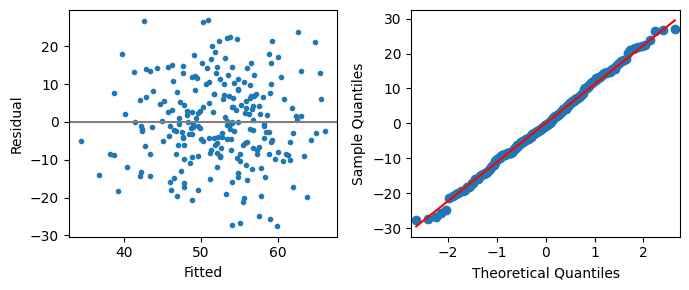

In [9]:
ctx.run('3-3', 'score_ols')